In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [14]:
df = pd.read_csv("/content/Dataset .csv")

In [24]:
print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

Dataset Loaded Successfully!
Dataset Shape: (9551, 25)


In [25]:
print("\nDataset Head:")
print(df.head())


Dataset Head:
   Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   
3        6318506                    Ooma           162  Mandaluyong City   
4        6314302             Sambo Kojin           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   
3  Third Floor, Mega Fashion Hall, SM Megamall, O...   
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong Cit

In [28]:
df = df[df['Aggregate rating'] > 0].copy()

# Select input features
features = [
    'Country Code',
    'City',
    'Cuisines',
    'Average Cost for two',
    'Currency',
    'Has Table booking',
    'Has Online delivery',
    'Price range',
    'Votes'
]

X = df[features]

# Target variable
y = df['Aggregate rating']

# Identify numerical and categorical columns
numeric_features = [
    'Country Code',
    'Average Cost for two',
    'Price range',
    'Votes'
]

categorical_features = [
    'City',
    'Cuisines',
    'Currency',
    'Has Table booking',
    'Has Online delivery'
]


numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


In [29]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)



Training Data: (5922, 9)
Testing Data: (1481, 9)


In [30]:
models = {
    'Linear Regression': LinearRegression(),

    'Decision Tree': DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )
}

In [31]:
results = []

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict ratings
    predictions = pipeline.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

    trained_models[name] = pipeline

    print("\nModel:", name)
    print("MAE:", round(mae, 3))
    print("MSE:", round(mse, 3))
    print("RMSE:", round(rmse, 3))
    print("R2 Score:", round(r2, 3))


Model: Linear Regression
MAE: 0.302
MSE: 0.148
RMSE: 0.385
R2 Score: 0.52

Model: Decision Tree
MAE: 0.277
MSE: 0.142
RMSE: 0.377
R2 Score: 0.541

Model: Random Forest
MAE: 0.251
MSE: 0.117
RMSE: 0.343
R2 Score: 0.62


In [32]:
results_df = pd.DataFrame(results)

print("\n========== MODEL COMPARISON ==========")

print(results_df.round(3))


========== MODEL COMPARISON ==========
               Model    MAE    MSE   RMSE  R2 Score
0  Linear Regression  0.302  0.148  0.385     0.520
1      Decision Tree  0.277  0.142  0.377     0.541
2      Random Forest  0.251  0.117  0.343     0.620


In [33]:
best_model_name = results_df.loc[
    results_df['R2 Score'].idxmax(),
    'Model'
]

print("\nBest Performing Model:", best_model_name)


Best Performing Model: Random Forest


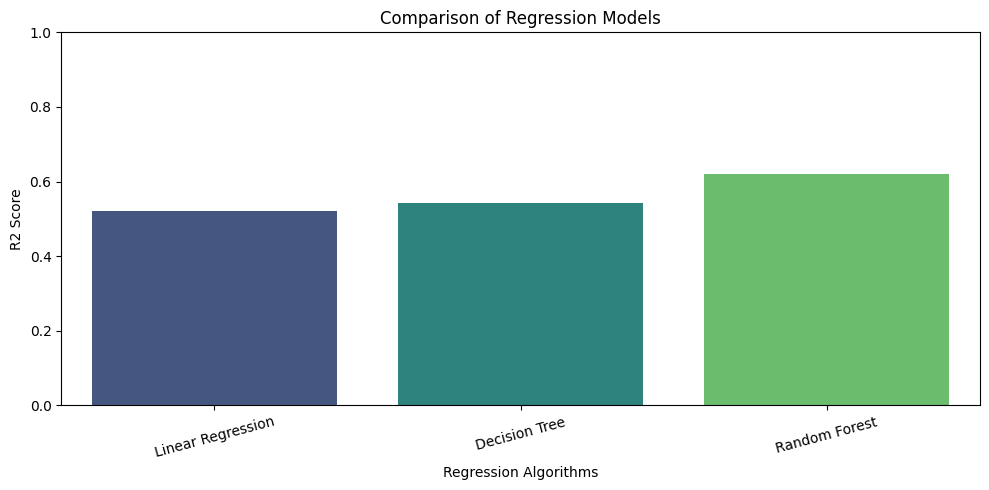

In [34]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='R2 Score',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title("Comparison of Regression Models")
plt.xlabel("Regression Algorithms")
plt.ylabel("R2 Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

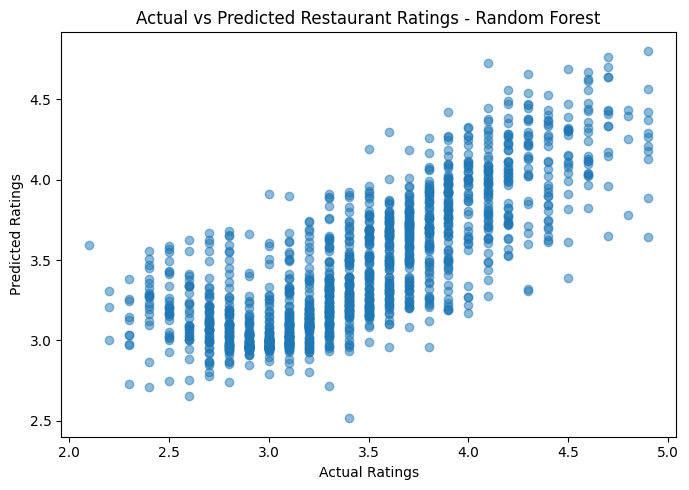

In [35]:
best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.5
)

plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")

plt.title(
    "Actual vs Predicted Restaurant Ratings - "
    + best_model_name
)

plt.tight_layout()
plt.show()

In [36]:

results_df.to_csv(
    "Predictive_Model_Comparison.csv",
    index=False
)

print("\nPredictive Modeling Completed Successfully!")
print("Results saved in Predictive_Model_Comparison.csv")


Predictive Modeling Completed Successfully!
Results saved in Predictive_Model_Comparison.csv
